# Data Visualization with the Tips Dataset

## Four questions
1. How are the total bills distributed?
2. Do tips differ by day of the week?
3. Does a bigger bill mean a bigger tip?
4. Which numbers move together?

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

tips = sns.load_dataset("tips")
print("Rows and columns:", tips.shape)
tips.head()

Rows and columns: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## Matching charts to questions
| Question | Chart | Why this chart |
|---|---|---|
| 1. How are total bills distributed? | Histogram | Shows how one number is spread across values |
| 2. Do tips differ by day? | Box plot | Compares a number across groups, showing the middle and the spread |
| 3. Does a bigger bill mean a bigger tip? | Scatter plot | Shows the relationship between two numbers |
| 4. Which numbers move together? | Correlation heatmap | Shows how strongly every pair of numbers is related |

In [2]:
tips.info()
print()
print("Missing values per column:")
print(tips.isna().sum())
tips.describe()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB

Missing values per column:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [3]:
# One theme and palette for every chart in this notebook
sns.set_theme(style="whitegrid", palette="colorblind")

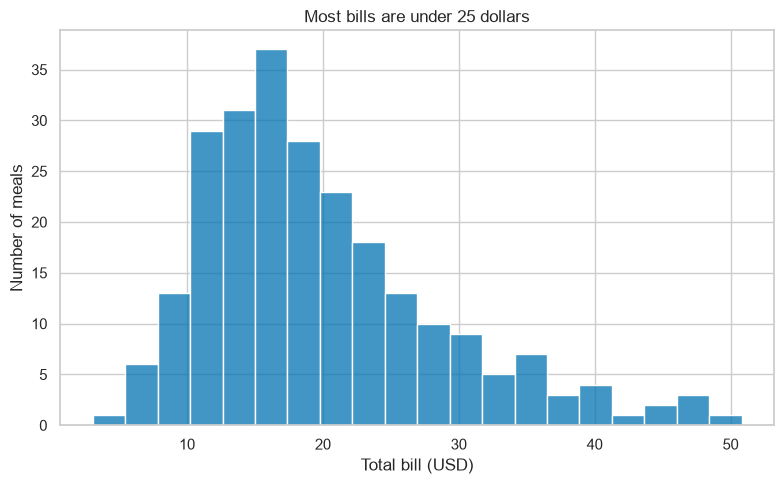

In [4]:
plt.figure(figsize=(8, 5))
sns.histplot(tips["total_bill"], bins=20)
plt.title("Most bills are under 25 dollars")
plt.xlabel("Total bill (USD)")
plt.ylabel("Number of meals")
plt.tight_layout()
plt.show()

**Takeaway:** Most bills fall between about 10 and 25 dollars and peak near 16 dollars, while a few bills above 40 dollars pull the average up to about 19.79 dollars.

      count  median  mean
day                      
Thur     62    2.30  2.77
Fri      19    3.00  2.73
Sat      87    2.75  2.99
Sun      76    3.15  3.26


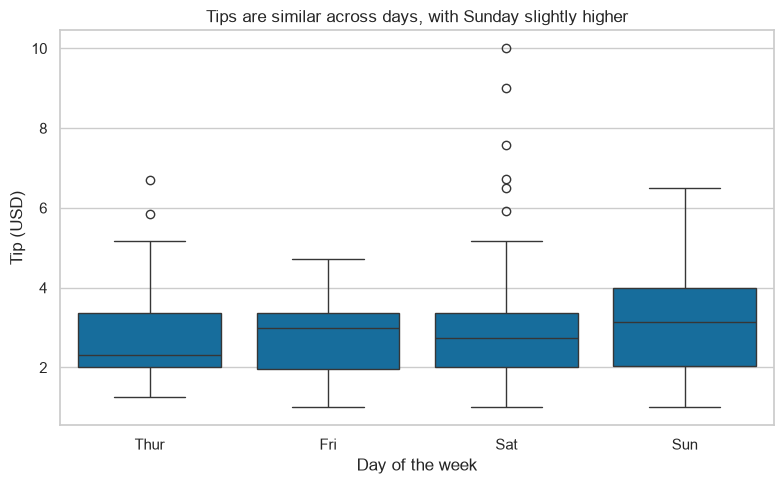

In [6]:
print(tips.groupby("day", observed=True)["tip"].agg(["count", "median", "mean"]).round(2))

plt.figure(figsize=(8, 5))
sns.boxplot(data=tips, x="day", y="tip")
plt.title("Tips are similar across days, with Sunday slightly higher")
plt.xlabel("Day of the week")
plt.ylabel("Tip (USD)")
plt.tight_layout()
plt.show()

**Takeaway:** Tips differ only slightly by day. Sunday has the highest median tip (3.15 USD) and the widest spread, while Thursday has the lowest (2.30 USD). Friday has only 19 meals, so its result is less reliable.

Correlation between bill and tip: 0.68


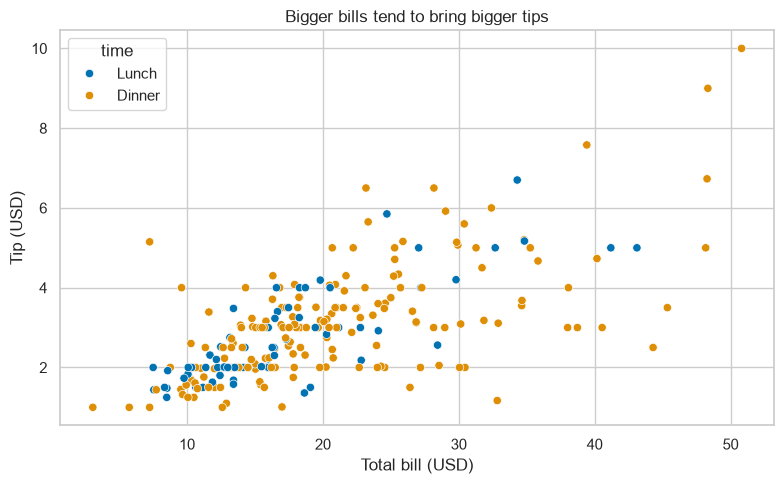

In [8]:
print("Correlation between bill and tip:", round(tips["total_bill"].corr(tips["tip"]), 2))

plt.figure(figsize=(8, 5))
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time")
plt.title("Bigger bills tend to bring bigger tips")
plt.xlabel("Total bill (USD)")
plt.ylabel("Tip (USD)")
plt.tight_layout()
plt.show()

**Takeaway:** Bigger bills tend to bring bigger tips (correlation 0.68), but the spread widens above 30 USD, so the bill alone doesn't predict the tip. Lunch and dinner follow the same pattern. This shows an association, not proof that one causes the other.

            total_bill   tip  size
total_bill        1.00  0.68  0.60
tip               0.68  1.00  0.49
size              0.60  0.49  1.00


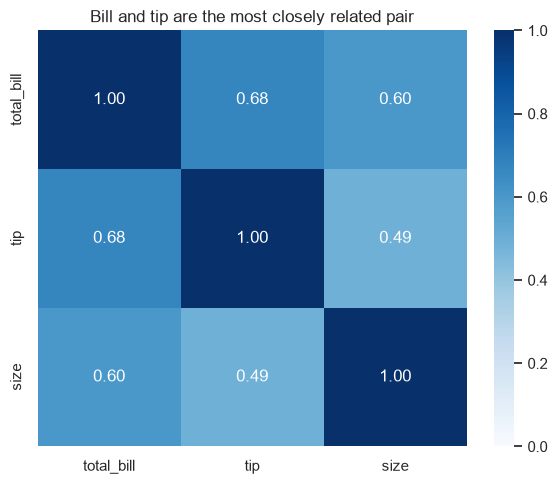

In [10]:
corr = tips.select_dtypes("number").corr()
print(corr.round(2))

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Bill and tip are the most closely related pair")
plt.tight_layout()
plt.show()

**Takeaway:** The strongest relationship is between total bill and tip (0.68), followed by bill and party size (0.60). Tip and party size are the least related of the three (0.49). All three are positive, but none is close to 1, so none of these numbers fully predicts another.

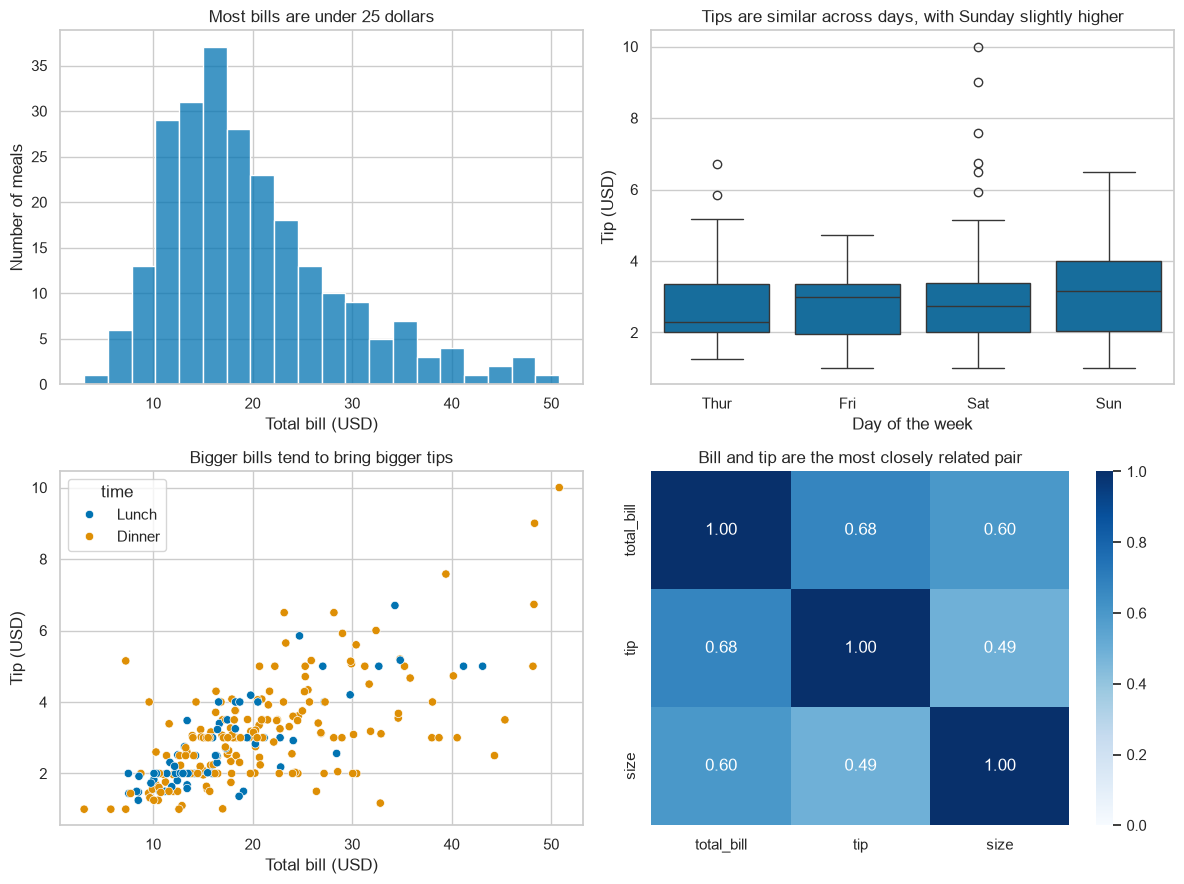

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Top left: histogram of bills
sns.histplot(tips["total_bill"], bins=20, ax=axes[0, 0])
axes[0, 0].set(title="Most bills are under 25 dollars",
               xlabel="Total bill (USD)", ylabel="Number of meals")

# Top right: tips by day
sns.boxplot(data=tips, x="day", y="tip", ax=axes[0, 1])
axes[0, 1].set(title="Tips are similar across days, with Sunday slightly higher",
               xlabel="Day of the week", ylabel="Tip (USD)")

# Bottom left: bill vs tip
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", ax=axes[1, 0])
axes[1, 0].set(title="Bigger bills tend to bring bigger tips",
               xlabel="Total bill (USD)", ylabel="Tip (USD)")

# Bottom right: correlation heatmap
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1, 1])
axes[1, 1].set_title("Bill and tip are the most closely related pair")

plt.tight_layout()
plt.savefig("tips_overview.png", dpi=150)
plt.show()

## Summary
![Tips dashboard](tips_overview.png)

**Takeaways**
1. Most bills fall between about 10 and 25 USD and peak near 16 USD.
2. Tips differ only slightly by day. Sunday has the highest median (3.15 USD).
3. Bigger bills tend to bring bigger tips (correlation 0.68), but the spread widens above 30 USD.
4. Bill and tip are the most closely related pair (0.68), followed by bill and party size (0.60).

## Review for honesty
- Every chart has a finding-style title, labelled axes and USD units.
- The histogram starts at zero and the heatmap colour scale runs from 0 to 1, so nothing is exaggerated.
- One colour-blind-friendly palette is used throughout, and no pie or 3D charts.
- Friday has only 19 meals, so its result is less reliable.
- Correlations show association, not cause.